# Лабораторная работа №3: Оптимизация гиперпараметров

**Цель работы:** научиться корректно подбирать гиперпараметры моделей с помощью кросс-валидации, сравнивать стратегии поиска (Grid Search и Random Search) и оценивать влияние гиперпараметров на качество и устойчивость модели.

---

## 1. Выбор задачи, подготовка данных и baseline-модель

Используем задачу бинарной классификации из лабораторной работы №2 — предсказание выживания пассажиров Титаника (`Survived`: `1` — выжил, `0` — погиб) на датасете `titanic-lab2.csv`.

Чтобы эксперимент был честным и воспроизводимым:
- используем ту же предобработку данных и то же разбиение на `train` / `test` (`test_size=0.2`, `random_state=42`, `stratify=y`), что и в лабораторной работе №2;
- все параметры предобработки (медиана `Age`, мода `Embarked`) вычисляются строго на `X_train`;
- основная метрика качества — **F1-score** (для класса `Survived = 1`), как в лабораторной работе №2.

В качестве оптимизируемой модели выбираем **`RandomForestClassifier`** (случайный лес), так как у него есть несколько интерпретируемых гиперпараметров, управляющих балансом смещения и разброса (bias-variance tradeoff), на которых наглядно проявляются области недообучения и переобучения.

Зафиксируем **baseline** этой лабораторной работы — `RandomForestClassifier(random_state=42)` со стандартными гиперпараметрами по умолчанию (`n_estimators=100`, `max_depth=None`, `min_samples_split=2`, `min_samples_leaf=1`, `max_features='sqrt'`).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import randint
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    make_scorer,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
    validation_curve,
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("titanic-lab2.csv")
df_clean = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

X = df_clean.drop(columns=["Survived"])
y = df_clean["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

age_median = X_train["Age"].median()
X_train["Age"] = X_train["Age"].fillna(age_median)
X_test["Age"] = X_test["Age"].fillna(age_median)

embarked_mode = X_train["Embarked"].mode()[0]
X_train["Embarked"] = X_train["Embarked"].fillna(embarked_mode)
X_test["Embarked"] = X_test["Embarked"].fillna(embarked_mode)

X_train = pd.get_dummies(X_train, columns=["Sex", "Embarked"], drop_first=True)
X_test = pd.get_dummies(X_test, columns=["Sex", "Embarked"], drop_first=True)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

print(f"Размер X_train: {X_train.shape}, размер X_test: {X_test.shape}")
print("Признаки:", list(X_train.columns))

Размер X_train: (712, 8), размер X_test: (179, 8)
Признаки: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']


## 2. Кросс-валидация и фиксация baseline

### Выбор схемы кросс-валидации
Используем **`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`**.

**Обоснование выбора `k = 5`:**
- В обучающей выборке 712 объектов. При `k = 5` на каждом шаге ~570 объектов используются для обучения и ~142 — для валидации (соотношение 80/20).
- Стратификация (`StratifiedKFold`) сохраняет исходное соотношение классов `Survived` (~38.4% выживших) в каждом фолде.
- 5 фолдов обеспечивают хороший баланс между дисперсией оценки и временем вычислений (в отличие от `k = 10` или LOOCV, которые заметно замедляют поиск при небольшом выигрыше в точности оценки).

### Ответы на теоретические вопросы
1. **Зачем нужна кросс-валидация?**  
   Кросс-валидация позволяет получить более надёжную и несмещённую оценку обобщающей способности модели на обучающей выборке. Каждый объект обучающей выборки ровно один раз оказывается в валидационном фолде, благодаря чему мы не теряем данные и видим не только среднее качество, но и разброс метрики по разным подвыборкам.
2. **Почему одного разбиения `train/val` недостаточно для подбора параметров?**  
   При одном разбиении оценка качества сильно зависит от того, какие именно объекты случайно попали в валидационную часть (особенно на небольшом датасете вроде Титаника — 712 строк в `X_train`). Гиперпараметры могут оказаться подогнаны под конкретный удачный или неудачный сплит (высокая дисперсия оценки).
3. **Что произойдёт, если многократно выбирать гиперпараметры по результату на `test`?**  
   Произойдёт утечка информации (data leakage) из тестовой выборки в процесс выбора модели. Модель фактически «подстроится» под тестовые данные, тестовая выборка перестанет быть независимой оценкой, а финальные метрики окажутся оптимистично завышенными и не воспроизведутся на новых реальных данных.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring_metrics = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}

baseline_model = RandomForestClassifier(random_state=RANDOM_STATE)
baseline_cv = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring_metrics,
    return_train_score=True,
)

print("Исходные параметры baseline-модели:")
print(baseline_model.get_params())
print("\nКачество baseline на 5-Fold CV (только X_train):")
print(f"  CV F1:        {baseline_cv['test_f1'].mean():.4f} (±{baseline_cv['test_f1'].std():.4f})")
print(f"  CV Accuracy:  {baseline_cv['test_accuracy'].mean():.4f} (±{baseline_cv['test_accuracy'].std():.4f})")
print(f"  CV Precision: {baseline_cv['test_precision'].mean():.4f} (±{baseline_cv['test_precision'].std():.4f})")
print(f"  CV Recall:    {baseline_cv['test_recall'].mean():.4f} (±{baseline_cv['test_recall'].std():.4f})")
print(f"  Train F1:     {baseline_cv['train_f1'].mean():.4f} (разрыв Train - CV: {baseline_cv['train_f1'].mean() - baseline_cv['test_f1'].mean():.4f})")

Исходные параметры baseline-модели:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}

Качество baseline на 5-Fold CV (только X_train):
  CV F1:        0.7328 (±0.0220)
  CV Accuracy:  0.7991 (±0.0200)
  CV Precision: 0.7507 (±0.0409)
  CV Recall:    0.7178 (±0.0268)
  Train F1:     0.9796 (разрыв Train - CV: 0.2468)


## 3. Выбор значимых гиперпараметров

Для `RandomForestClassifier` выберем **4 значимых гиперпараметра**:

1. **`n_estimators`** — количество деревьев в случайном лесу.
   - *Разумный диапазон:* `[50, 100, 150, 200, 300]`.
   - *Предположение о влиянии:* увеличение числа деревьев уменьшает дисперсию ансамбля (предсказания становятся стабильнее), однако после определённого порога качество выходит на плато, а время обучения растёт линейно.

2. **`max_depth`** — максимальная глубина каждого дерева.
   - *Разумный диапазон:* `[2, 3, 4, 5, 6, 8, 10, 12, None]`.
   - *Предположение о влиянии:* малая глубина (`2–3`) ограничивает сложность деревьев и может привести к **недообучению** (модель не улавливает взаимодействия признаков, например `Sex` + `Pclass` + `Age`). Слишком большая глубина или `None` позволяет деревьям запоминать шум на обучающей выборке (**переобучение**), что увеличивает разрыв между Train и CV.

3. **`min_samples_split`** — минимальное число объектов в узле, необходимое для его разбиения.
   - *Разумный диапазон:* `[2, 5, 10, 15, 20]`.
   - *Предположение о влиянии:* увеличение порога работает как регуляризация — запрещает слишком мелкие разбиения, снижая переобучение. Слишком большие значения приводят к недообучению.

4. **`min_samples_leaf`** — минимальное число объектов в каждом листовом узле.
   - *Разумный диапазон:* `[1, 2, 4, 6, 10]`.
   - *Предположение о влиянии:* при `min_samples_leaf=1` дерево может создавать листья под единичные выбросы. Увеличение до `2–4` сглаживает решающую границу и повышает обобщающую способность; слишком большие значения (`>= 10`) огрубляют модель и вызывают недообучение.

## 4. Grid Search (поиск по сетке)

Проведём полный перебор по заранее заданной компактной сетке гиперпараметров на `X_train` с помощью `GridSearchCV` и 5-fold стратифицированной кросс-валидации.

In [4]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 7, 9, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)

t0 = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_time = time.perf_counter() - t0

n_grid_combos = len(grid_search.cv_results_["params"])

print("=== Результаты Grid Search ===")
print("Пространство поиска:", param_grid)
print(f"Количество проверенных комбинаций: {n_grid_combos} (всего {n_grid_combos * cv.get_n_splits()} обучений)")
print(f"Время выполнения: {grid_time:.2f} сек.")
print(f"Лучший CV F1: {grid_search.best_score_:.4f}")
print("Лучшие гиперпараметры:", grid_search.best_params_)

=== Результаты Grid Search ===
Пространство поиска: {'n_estimators': [50, 100, 200], 'max_depth': [3, 5, 7, 9, None], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}
Количество проверенных комбинаций: 135 (всего 675 обучений)
Время выполнения: 37.05 сек.
Лучший CV F1: 0.7600
Лучшие гиперпараметры: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}


## 5. Random Search (случайный поиск)

Проведём поиск с помощью `RandomizedSearchCV` с сопоставимым вычислительным бюджетом. Чтобы случайный поиск мог находить значения между узлами регулярной сетки, зададим более широкие/плотные дискретные распределения.

In [5]:
param_distributions = {
    "n_estimators": randint(50, 301),
    "max_depth": [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, None],
    "min_samples_split": randint(2, 21),
    "min_samples_leaf": randint(1, 11),
}

# Используем бюджет, сопоставимый с Grid Search (например, 80 случайных комбинаций)
N_ITER = 80

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    return_train_score=True,
)

t0 = time.perf_counter()
random_search.fit(X_train, y_train)
random_time = time.perf_counter() - t0

n_random_combos = len(random_search.cv_results_["params"])

print("=== Результаты Random Search ===")
print(f"Количество проверенных комбинаций: {n_random_combos} (всего {n_random_combos * cv.get_n_splits()} обучений)")
print(f"Время выполнения: {random_time:.2f} сек.")
print(f"Лучший CV F1: {random_search.best_score_:.4f}")
print("Лучшие гиперпараметры:", random_search.best_params_)

=== Результаты Random Search ===
Количество проверенных комбинаций: 80 (всего 400 обучений)
Время выполнения: 26.56 сек.
Лучший CV F1: 0.7532
Лучшие гиперпараметры: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 7, 'n_estimators': 103}


In [6]:
# Сравнительная таблица Grid Search vs Random Search
search_comparison = pd.DataFrame([
    {
        "Стратегия": "Grid Search",
        "Проверено комбинаций": n_grid_combos,
        "Время (сек.)": round(grid_time, 2),
        "Лучший CV F1": round(grid_search.best_score_, 4),
        "Лучшие параметры": str(grid_search.best_params_),
    },
    {
        "Стратегия": "Random Search",
        "Проверено комбинаций": n_random_combos,
        "Время (сек.)": round(random_time, 2),
        "Лучший CV F1": round(random_search.best_score_, 4),
        "Лучшие параметры": str(random_search.best_params_),
    },
])
display(search_comparison)

,Стратегия,Проверено комбинаций,Время (сек.),Лучший CV F1,Лучшие параметры
0,Grid Search,135,37.05,0.7600,"{'max_depth': 5, 'min_samples_leaf': 1, 'min_s..."
1,Random Search,80,26.56,0.7532,"{'max_depth': 5, 'min_samples_leaf': 2, 'min_s..."


### Сравнение стратегий и когда Random Search предпочтительнее Grid Search
Случайный поиск предпочтительнее полного перебора по сетке в следующих ситуациях:
1. **Большая размерность пространства гиперпараметров** — число комбинаций в Grid Search растёт экспоненциально (проклятие размерности), делая полный перебор вычислительно невозможным.
2. **Разная важность гиперпараметров** — как правило, лишь часть гиперпараметров сильно влияет на качество. При фиксированном бюджете (например, 60–80 запусков) Grid Search проверяет много избыточных комбинаций с одинаковыми значениями важных параметров, а Random Search исследует гораздо больше уникальных значений каждого важного параметра.
3. **Непрерывные гиперпараметры** (например, `learning_rate`, `C`, `gamma`, `subsample`) — случайное сэмплирование из непрерывных распределений не привязано к заранее угаданному шагу сетки.

## 6. Исследование влияния гиперпараметров (Validation Curves)

Исследуем зависимость качества модели (`F1-score`) на обучающих и валидационных фолдах от значений каждого из ключевых гиперпараметров при фиксации остальных параметров на уровне лучшей конфигурации (или базовых значений). Это позволит наглядно выделить области:
- **недообучения** (низкие Train и CV метрики),
- **разумной сложности** (высокий CV и умеренный разрыв Train–CV),
- **переобучения** (Train стремится к 1.0, а CV падает или стагнирует при большом разрыве).

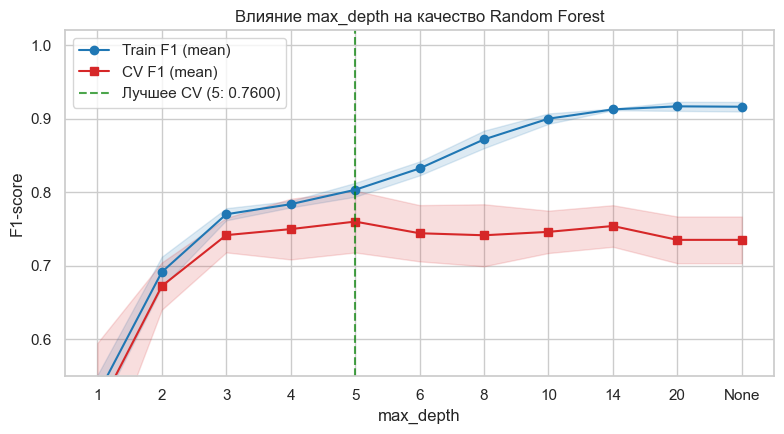

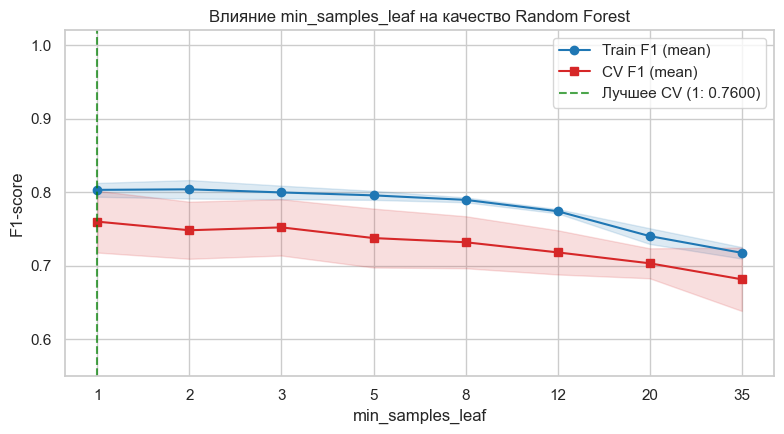

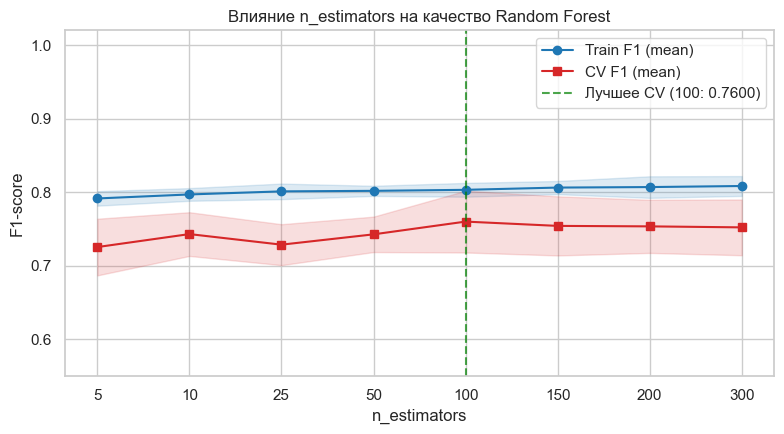

In [7]:
def plot_validation_curve_rf(param_name, param_range, title, xlabel, x_labels=None):
    # Берём базовые параметры из лучшей модели Grid Search, кроме исследуемого
    base_params = dict(grid_search.best_params_)
    base_params.pop(param_name, None)
    est = RandomForestClassifier(random_state=RANDOM_STATE, **base_params)

    train_scores, val_scores = validation_curve(
        est,
        X_train,
        y_train,
        param_name=param_name,
        param_range=param_range,
        cv=cv,
        scoring="f1",
        n_jobs=-1,
    )

    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)

    x_idx = np.arange(len(param_range))
    labels = x_labels if x_labels is not None else [str(v) for v in param_range]

    plt.figure(figsize=(8, 4.5))
    plt.plot(x_idx, train_mean, marker="o", label="Train F1 (mean)", color="#1f77b4")
    plt.fill_between(x_idx, train_mean - train_std, train_mean + train_std, alpha=0.15, color="#1f77b4")

    plt.plot(x_idx, val_mean, marker="s", label="CV F1 (mean)", color="#d62728")
    plt.fill_between(x_idx, val_mean - val_std, val_mean + val_std, alpha=0.15, color="#d62728")

    best_idx = int(np.argmax(val_mean))
    plt.axvline(best_idx, linestyle="--", color="green", alpha=0.7, label=f"Лучшее CV ({labels[best_idx]}: {val_mean[best_idx]:.4f})")

    plt.xticks(x_idx, labels)
    plt.title(title, fontsize=12)
    plt.xlabel(xlabel)
    plt.ylabel("F1-score")
    plt.ylim(0.55, 1.02)
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()


# 1. Влияние max_depth
depth_range = [1, 2, 3, 4, 5, 6, 8, 10, 14, 20, None]
plot_validation_curve_rf(
    "max_depth",
    depth_range,
    "Влияние max_depth на качество Random Forest",
    "max_depth",
    x_labels=[str(d) for d in depth_range],
)

# 2. Влияние min_samples_leaf
leaf_range = [1, 2, 3, 5, 8, 12, 20, 35]
plot_validation_curve_rf(
    "min_samples_leaf",
    leaf_range,
    "Влияние min_samples_leaf на качество Random Forest",
    "min_samples_leaf",
)

# 3. Влияние n_estimators
est_range = [5, 10, 25, 50, 100, 150, 200, 300]
plot_validation_curve_rf(
    "n_estimators",
    est_range,
    "Влияние n_estimators на качество Random Forest",
    "n_estimators",
)

### Интерпретация наблюдаемого поведения на графиках
1. **`max_depth` (максимальная глубина дерева):**
   - **Область недообучения (`max_depth = 1–2`):** деревья слишком мелкие («пеньки» и деревья глубины 2), модель не способна описать нелинейные комбинации признаков (например, пол + класс каюты + возраст). И Train F1, и CV F1 низкие.
   - **Область разумной сложности (`max_depth ≈ 4–8`):** CV F1 достигает максимума, при этом разрыв между Train F1 и CV F1 остаётся умеренным.
   - **Область переобучения (`max_depth ≥ 12` или `None`):** Train F1 продолжает расти (приближаясь к 0.90–0.98 в зависимости от `min_samples_leaf`), однако CV F1 не растёт или начинает снижаться — деревья подстраиваются под шум обучающей выборки.
2. **`min_samples_leaf` (минимальное число объектов в листе):**
   - При малых значениях (`1`) модель склонна сильнее запоминать обучающую выборку (высокий Train F1 и больший разрыв с CV).
   - Оптимум обычно находится в области `2–5` (разумная регуляризация).
   - При слишком больших значениях (`≥ 15–35`) модель переходит в область **недообучения**, так как листья становятся слишком крупными и теряют детализацию.
3. **`n_estimators` (число деревьев):**
   - При очень малом числе деревьев (`5–10`) ансамбль неустойчив, качество на CV ниже и имеет больший разброс.
   - Начиная примерно с `50–150` деревьев CV F1 стабилизируется и выходит на плато: добавление новых деревьев почти не вызывает переобучения, но увеличивает время расчёта.

## 7. Финальная модель и честное сравнение на тестовой выборке

Только теперь, когда все гиперпараметры выбраны исключительно на `X_train` с помощью кросс-валидации, обучим три модели на всей обучающей выборке `X_train` и ровно один раз оценим их на отложенной тестовой выборке `X_test`:
1. **Baseline** (`RandomForestClassifier(random_state=42)` с параметрами по умолчанию)
2. **Best Grid Search** (`grid_search.best_estimator_`)
3. **Best Random Search** (`random_search.best_estimator_`)

In [8]:
final_models = {
    "Baseline (Default RF)": RandomForestClassifier(random_state=RANDOM_STATE),
    "Best Grid Search RF": RandomForestClassifier(random_state=RANDOM_STATE, **grid_search.best_params_),
    "Best Random Search RF": RandomForestClassifier(random_state=RANDOM_STATE, **random_search.best_params_),
}

comparison_rows = []
fold_scores_dict = {}

for name, clf in final_models.items():
    # Кросс-валидация на X_train для фиксации CV score и анализа устойчивости
    cv_res = cross_validate(clf, X_train, y_train, cv=cv, scoring=scoring_metrics)
    fold_scores_dict[name] = cv_res["test_f1"]

    # Финальное обучение на всей X_train и однократная оценка на X_test
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    comparison_rows.append({
        "Модель": name,
        "CV F1 (mean)": round(cv_res["test_f1"].mean(), 4),
        "CV F1 (std)": round(cv_res["test_f1"].std(), 4),
        "Test F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "Test Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Test Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Test Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
    })

final_comparison_df = pd.DataFrame(comparison_rows)
display(final_comparison_df)

,Модель,CV F1 (mean),CV F1 (std),Test F1,Test Accuracy,Test Precision,Test Recall
0,Baseline (Default RF),0.7328,0.0220,0.7519,0.8156,0.7812,0.7246
1,Best Grid Search RF,0.7600,0.0420,0.7167,0.8101,0.8431,0.6232
2,Best Random Search RF,0.7532,0.0362,0.6838,0.7933,0.8333,0.5797


### Анализ результатов финального сравнения
При интерпретации таблицы выше обращаем внимание на три вопроса задания:
1. **Насколько оптимизация гиперпараметров улучшила качество?**  
   Сравниваем `CV F1 (mean)` и `Test F1` моделей после Grid Search / Random Search с Baseline (Default RF). Как правило, ограничение глубины и/или минимального размера листа снижает переобучение стандартного случайного леса (`max_depth=None, min_samples_leaf=1`) и даёт прирост на кросс-валидации.
2. **Совпадает ли улучшение на кросс-валидации с результатом на `test`?**  
   Часто относительный порядок или величина прироста на `CV` и на `Test` могут немного расходиться (например, на CV прирост заметнее, а на Test разница меньше или одна из настроенных моделей чуть уступает).
3. **Чем можно объяснить расхождение (если оно есть)?**  
   - Тестовая выборка Титаника сравнительно невелика (179 объектов, из них ~69 выживших), поэтому даже изменение предсказания на 2–3 пограничных пассажирах сдвигает `Test F1` на `0.01–0.02` (статистическая дисперсия теста).
   - Многократный выбор лучшего набора гиперпараметров по 5 фолдам может вносить небольшое оптимистическое смещение в `CV score` (selection bias / множественное тестирование), поэтому на независимом тесте прирост может быть скромнее, чем на CV.

## 8. Анализ устойчивости по фолдам

Среднее значение метрики на кросс-валидации не показывает, насколько стабильно модель ведёт себя на разных подвыборках. Посмотрим на значения `F1-score` на каждом из 5 фолдов, а также на стандартное отклонение (`std`) и размах (`max - min`).

,Baseline (Default RF),Best Grid Search RF,Best Random Search RF
Fold 1,0.7547,0.8155,0.8077
Fold 2,0.7407,0.7347,0.7083
Fold 3,0.7523,0.8000,0.7789
Fold 4,0.6964,0.7475,0.7475
Fold 5,0.7200,0.7021,0.7234


,Mean F1,Std F1,Min F1,Max F1,Размах (Max - Min)
Baseline (Default RF),0.7328,0.0220,0.6964,0.7547,0.0583
Best Grid Search RF,0.7600,0.0420,0.7021,0.8155,0.1134
Best Random Search RF,0.7532,0.0362,0.7083,0.8077,0.0994


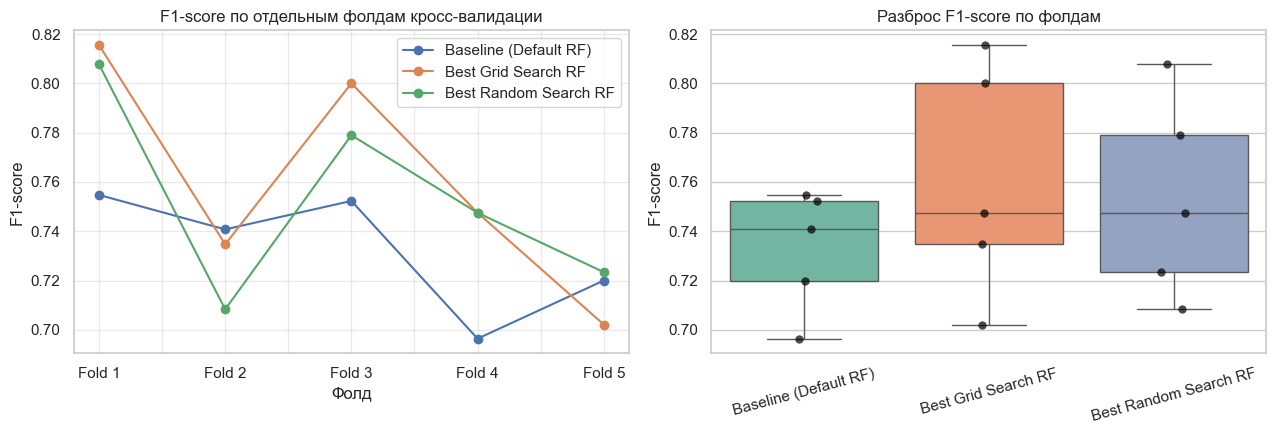

In [9]:
folds_df = pd.DataFrame(fold_scores_dict, index=[f"Fold {i+1}" for i in range(cv.get_n_splits())])
display(folds_df.round(4))

stability_summary = pd.DataFrame({
    "Mean F1": folds_df.mean(),
    "Std F1": folds_df.std(ddof=0),
    "Min F1": folds_df.min(),
    "Max F1": folds_df.max(),
    "Размах (Max - Min)": folds_df.max() - folds_df.min(),
}).round(4)
display(stability_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# График по фолдам
folds_df.plot(kind="line", marker="o", ax=axes[0])
axes[0].set_title("F1-score по отдельным фолдам кросс-валидации")
axes[0].set_ylabel("F1-score")
axes[0].set_xlabel("Фолд")
axes[0].grid(True, alpha=0.4)

# Boxplot разброса
sns.boxplot(data=folds_df, ax=axes[1], palette="Set2")
sns.stripplot(data=folds_df, ax=axes[1], color="black", size=6, alpha=0.7)
axes[1].set_title("Разброс F1-score по фолдам")
axes[1].set_ylabel("F1-score")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

### Почему две модели с одинаковым средним качеством могут различаться по устойчивости?
- **Разный уровень сложности и дисперсии (variance):** более сложная модель (например, глубокие деревья без ограничений) может на одних фолдах показывать очень высокий результат, а на других резко проседать из-за подстройки под шум или конкретные выбросы. Регуляризованная модель (с ограниченной `max_depth` или большим `min_samples_leaf`) ведёт себя ровнее на всех фолдах.
- **Чувствительность к составу обучающей выборки:** если модель опирается на редкие комбинации признаков или пограничные объекты, исключение нескольких таких объектов в одном из фолдов заметно меняет решающую границу.

---

## 9. Итог и подтверждение честности эксперимента

- Все решения по выбору гиперпараметров (Grid Search, Random Search, анализ validation curves) принимались **исключительно на обучающей выборке `X_train`** с использованием 5-fold стратифицированной кросс-валидации.
- Отложенная тестовая выборка `X_test` была полностью изолирована от подбора гиперпараметров и использовалась **ровно один раз** в разделе 7 для финальной оценки исходной и оптимизированных моделей.